In [1]:
#Load the analytical libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Read in the data
data = pd.read_csv("C:\\Users\\Nyakonda Patricia\\AppData\\Roaming\\MetaQuotes\\Terminal\\D0E8209F77C8CF37AD8BF550E51FF075\\MQL5\\Files\\EURUSD Bollinger Band RSI Data.csv")

In [3]:
#Drop the dates that overlap with our backtest
train = data.iloc[:((-365 * 2) - 90),:]
test  = data.iloc[((-365 * 2) - 90):,:]

#Check the dates left
train

,Time,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI
0,2011.12.22 00:00:00,1.30438,1.31183,1.30171,1.30507,1.372738,1.331909,1.291079,36.747408
1,2011.12.23 00:00:00,1.30503,1.30946,1.30259,1.30451,1.367923,1.329502,1.291080,36.518142
2,2011.12.26 00:00:00,1.30487,1.30813,1.30487,1.30540,1.364997,1.327612,1.290226,37.185468
3,2011.12.27 00:00:00,1.30537,1.30824,1.30422,1.30676,1.363014,1.326086,1.289159,38.248263
4,2011.12.28 00:00:00,1.30677,1.30791,1.29116,1.29362,1.362333,1.324358,1.286383,32.547572
...,...,...,...,...,...,...,...,...,...
2824,2022.11.08 00:00:00,1.00169,1.00964,0.99717,1.00729,1.006551,0.985073,0.963595,59.436093
2825,2022.11.09 00:00:00,1.00715,1.00882,0.99927,1.00120,1.007783,0.985997,0.964211,55.853343
2826,2022.11.10 00:00:00,1.00094,1.02220,0.99355,1.02093,1.012366,0.987312,0.962259,63.492151
2827,2022.11.11 00:00:00,1.02062,1.03642,1.01629,1.03530,1.019387,0.989159,0.958931,67.835260


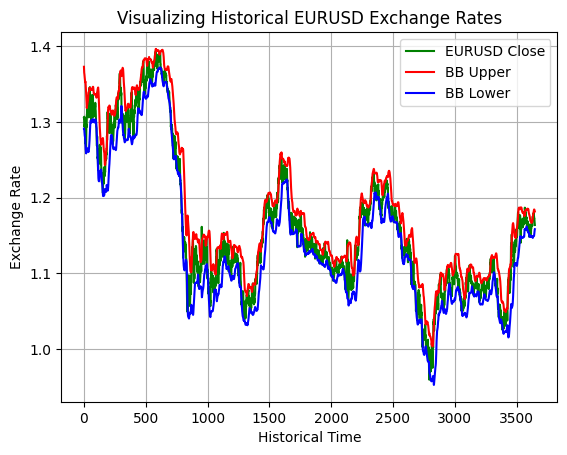

In [4]:
plt.plot(data['Close'],color='green')
plt.plot(data['BB Upper'],color='red')
plt.plot(data['BB Lower'],color='blue')
plt.grid()
plt.title('Visualizing Historical EURUSD Exchange Rates')
plt.ylabel('Exchange Rate')
plt.xlabel('Historical Time')
plt.legend(['EURUSD Close','BB Upper','BB Lower'])

In [5]:
#Load our machine learning training libraries
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ARDRegression
from sklearn.neighbors    import KNeighborsRegressor,RadiusNeighborsRegressor
from sklearn.svm          import LinearSVR
from sklearn.ensemble     import RandomForestRegressor,BaggingRegressor,AdaBoostRegressor
from sklearn.model_selection import TimeSeriesSplit,cross_val_score

In [6]:
#Define our forecast horizon
HORIZON = 5

In [7]:
#Label the data
train['Target 1'] = train['BB Upper'].shift(-HORIZON)
train['Target 2'] = train['BB Mid'].shift(-HORIZON)
train['Target 3'] = train['BB Lower'].shift(-HORIZON)
train['Target 4'] = train['RSI'].shift(-HORIZON)

C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\577210540.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Target 1'] = train['BB Upper'].shift(-HORIZON)
C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\577210540.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Target 2'] = train['BB Mid'].shift(-HORIZON)
C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\577210540.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a

In [8]:
train['Bin Target Threshold Price'] = 0
train['Bin Target Threshold BB Mid'] = 0
train['Bin Target Threshold RSI'] = 0

train.loc[train['Close'].shift(-HORIZON) > train['Close'],'Bin Target Threshold Price'] = 1
train.loc[train['BB Mid'].shift(-HORIZON) > train['BB Mid'],'Bin Target Threshold BB Mid'] = 1
train.loc[train['RSI'].shift(-HORIZON) > train['RSI'],'Bin Target Threshold RSI'] = 1

C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\1269895373.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Bin Target Threshold Price'] = 0
C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\1269895373.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Bin Target Threshold BB Mid'] = 0
C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\1269895373.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using 

In [9]:
#Drop missing labels
train = train.iloc[:-HORIZON*2,:]
train

,Time,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI,Target 1,Target 2,Target 3,Target 4,Bin Target Threshold Price,Bin Target Threshold BB Mid,Bin Target Threshold RSI
0,2011.12.22 00:00:00,1.30438,1.31183,1.30171,1.30507,1.372738,1.331909,1.291079,36.747408,1.361063,1.322630,1.284197,33.699789,0,0,0
1,2011.12.23 00:00:00,1.30503,1.30946,1.30259,1.30451,1.367923,1.329502,1.291080,36.518142,1.358734,1.320745,1.282755,34.205041,0,0,0
2,2011.12.26 00:00:00,1.30487,1.30813,1.30487,1.30540,1.364997,1.327612,1.290226,37.185468,1.356674,1.318906,1.281138,33.180078,0,0,0
3,2011.12.27 00:00:00,1.30537,1.30824,1.30422,1.30676,1.363014,1.326086,1.289159,38.248263,1.353412,1.317356,1.281301,42.674347,0,0,1
4,2011.12.28 00:00:00,1.30677,1.30791,1.29116,1.29362,1.362333,1.324358,1.286383,32.547572,1.352429,1.315989,1.279549,37.132462,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2814,2022.10.25 00:00:00,0.98712,0.99769,0.98482,0.99644,1.005396,0.982281,0.959167,57.257790,1.003442,0.981559,0.959675,49.879315,0,0,0
2815,2022.10.26 00:00:00,0.99620,1.00889,0.99433,1.00826,1.006914,0.982619,0.958323,62.742030,1.003360,0.981491,0.959622,46.606188,0,0,0
2816,2022.10.27 00:00:00,1.00746,1.00933,0.99574,0.99634,1.006521,0.982508,0.958495,55.102714,1.003163,0.981190,0.959216,43.060989,0,0,0
2817,2022.10.28 00:00:00,0.99631,0.99981,0.99265,0.99657,1.005927,0.982351,0.958774,55.215444,1.004188,0.982094,0.960001,54.550446,0,0,0


Text(0.5, 1.0, 'Relationship Between RSI & EURUSD Return')

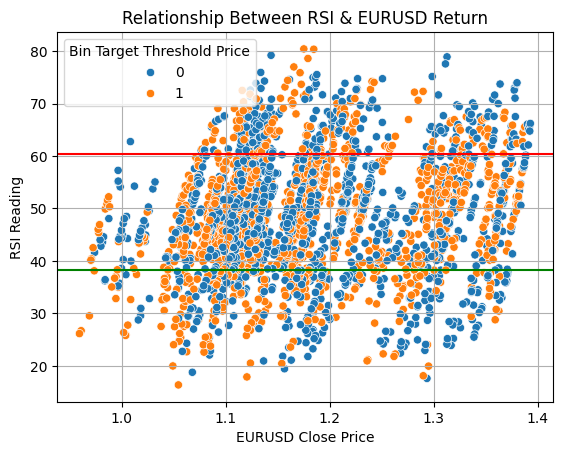

In [14]:
sns.scatterplot(data=train,x='Close',y='RSI',hue='Bin Target Threshold Price')
plt.axhline(data['RSI'].mean()+data['RSI'].std(),color='red')
plt.axhline(data['RSI'].mean()-data['RSI'].std(),color='green')
plt.grid()
plt.ylabel('RSI Reading')
plt.xlabel('EURUSD Close Price')
plt.title('Relationship Between RSI & EURUSD Return')

Text(0.5, 1.0, 'Relationship Between EURUSD Close & BB Upper')

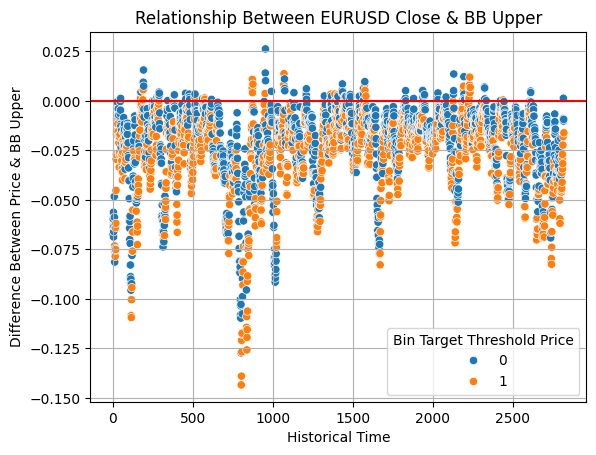

In [17]:
sns.scatterplot(data=train,y=train['Close']-train['BB Upper'],x=np.arange(train.shape[0]),hue='Bin Target Threshold Price')
plt.grid()
plt.axhline(0,color='red')
plt.ylabel('Difference Between Price & BB Upper')
plt.xlabel('Historical Time')
plt.title('Relationship Between EURUSD Close & BB Upper')

Text(0.5, 1.0, 'Relationship Between EURUSD Close & BB Lower')

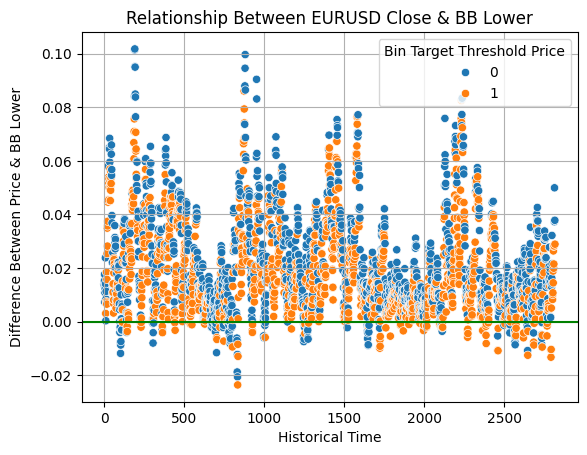

In [18]:
sns.scatterplot(data=train,y=train['Close']-train['BB Lower'],x=np.arange(train.shape[0]),hue='Bin Target Threshold Price')
plt.axhline(0,color='green')
plt.grid()
plt.ylabel('Difference Between Price & BB Lower')
plt.xlabel('Historical Time')
plt.title('Relationship Between EURUSD Close & BB Lower')

In [19]:
train.iloc[:,1:9]

,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI
0,1.30438,1.31183,1.30171,1.30507,1.372738,1.331909,1.291079,36.747408
1,1.30503,1.30946,1.30259,1.30451,1.367923,1.329502,1.291080,36.518142
2,1.30487,1.30813,1.30487,1.30540,1.364997,1.327612,1.290226,37.185468
3,1.30537,1.30824,1.30422,1.30676,1.363014,1.326086,1.289159,38.248263
4,1.30677,1.30791,1.29116,1.29362,1.362333,1.324358,1.286383,32.547572
...,...,...,...,...,...,...,...,...
2814,0.98712,0.99769,0.98482,0.99644,1.005396,0.982281,0.959167,57.257790
2815,0.99620,1.00889,0.99433,1.00826,1.006914,0.982619,0.958323,62.742030
2816,1.00746,1.00933,0.99574,0.99634,1.006521,0.982508,0.958495,55.102714
2817,0.99631,0.99981,0.99265,0.99657,1.005927,0.982351,0.958774,55.215444


In [20]:
#List all the models we wish to evaluate
models = [LinearRegression(),Ridge(),Lasso(),ARDRegression(),KNeighborsRegressor(),RadiusNeighborsRegressor(),LinearSVR(),RandomForestRegressor(),BaggingRegressor(),AdaBoostRegressor()]

In [21]:
#Define a time series cross validation object
tscv = TimeSeriesSplit(
  n_splits=5,
  gap=HORIZON
)

In [22]:
#Store the performance of each model
scores = []

In [23]:
train.iloc[:,1:9]

,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI
0,1.30438,1.31183,1.30171,1.30507,1.372738,1.331909,1.291079,36.747408
1,1.30503,1.30946,1.30259,1.30451,1.367923,1.329502,1.291080,36.518142
2,1.30487,1.30813,1.30487,1.30540,1.364997,1.327612,1.290226,37.185468
3,1.30537,1.30824,1.30422,1.30676,1.363014,1.326086,1.289159,38.248263
4,1.30677,1.30791,1.29116,1.29362,1.362333,1.324358,1.286383,32.547572
...,...,...,...,...,...,...,...,...
2814,0.98712,0.99769,0.98482,0.99644,1.005396,0.982281,0.959167,57.257790
2815,0.99620,1.00889,0.99433,1.00826,1.006914,0.982619,0.958323,62.742030
2816,1.00746,1.00933,0.99574,0.99634,1.006521,0.982508,0.958495,55.102714
2817,0.99631,0.99981,0.99265,0.99657,1.005927,0.982351,0.958774,55.215444


In [24]:
train.iloc[:,9:13]

,Target 1,Target 2,Target 3,Target 4
0,1.361063,1.322630,1.284197,33.699789
1,1.358734,1.320745,1.282755,34.205041
2,1.356674,1.318906,1.281138,33.180078
3,1.353412,1.317356,1.281301,42.674347
4,1.352429,1.315989,1.279549,37.132462
...,...,...,...,...
2814,1.003442,0.981559,0.959675,49.879315
2815,1.003360,0.981491,0.959622,46.606188
2816,1.003163,0.981190,0.959216,43.060989
2817,1.004188,0.982094,0.960001,54.550446


In [25]:
train.iloc[:,13:16]

,Bin Target Threshold Price,Bin Target Threshold BB Mid,Bin Target Threshold RSI
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,1
4,0,0,1
...,...,...,...
2814,0,0,0
2815,0,0,0
2816,0,0,0
2817,0,0,0


In [26]:
#Evaluate each model
for model in models:
  #User feedback
  print("Evaluating model: ",model)
  #Store the current score
  current_score = np.mean(np.abs(cross_val_score(model,train.iloc[:,1:-1],train.iloc[:,-1],cv=tscv,scoring='neg_mean_squared_error')))
  scores.append(current_score)

Evaluating model:  LinearRegression()
Evaluating model:  Ridge()
Evaluating model:  Lasso()
Evaluating model:  ARDRegression()
Evaluating model:  KNeighborsRegressor()
Evaluating model:  RadiusNeighborsRegressor()


C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\numeric.py:476: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\numeric.py:476: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\numeric.py:476: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\numeric.py:476: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\numeric.py:476: RuntimeWarning:

Evaluating model:  LinearSVR()


C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\Nyakonda Patricia\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear fa

Evaluating model:  RandomForestRegressor()
Evaluating model:  BaggingRegressor()
Evaluating model:  AdaBoostRegressor()


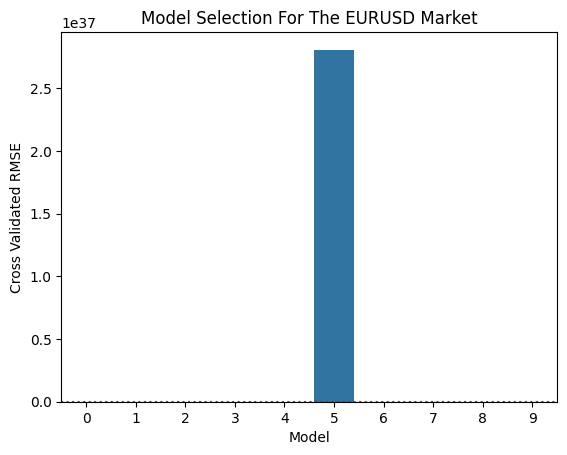

In [27]:
sns.barplot(scores)
plt.ylabel('Cross Validated RMSE')
plt.xlabel('Model')
plt.title('Model Selection For The EURUSD Market')
plt.axhline(scores[3],linestyle=':',color='red')

In [28]:
scores

[np.float64(0.06981951535482404),
 np.float64(0.06945865136509487),
 np.float64(0.13955012927335617),
 np.float64(0.06903782424995906),
 np.float64(0.017501066098081025),
 np.float64(2.8078736886653132e+37),
 np.float64(0.09095551809072663),
 np.float64(0.04297449893390192),
 np.float64(0.05350533049040512),
 np.float64(0.08979615491147575)]

In [241]:
#The model we have selected is ARDRegression
models[3]

,"max_iter max_iter: int, default=300Maximum number of iterations... versionchanged:: 1.3",300
,"tol tol: float, default=1e-3Stop the algorithm if w has converged.",0.001
,"alpha_1 alpha_1: float, default=1e-6Hyper-parameter : shape parameter for the Gamma distribution priorover the alpha parameter.",1e-06
,"alpha_2 alpha_2: float, default=1e-6Hyper-parameter : inverse scale parameter (rate parameter) for theGamma distribution prior over the alpha parameter.",1e-06
,"lambda_1 lambda_1: float, default=1e-6Hyper-parameter : shape parameter for the Gamma distribution priorover the lambda parameter.",1e-06
,"lambda_2 lambda_2: float, default=1e-6Hyper-parameter : inverse scale parameter (rate parameter) for theGamma distribution prior over the lambda parameter.",1e-06
,"compute_score compute_score: bool, default=FalseIf True, compute the objective function at each step of the model.",False
,"threshold_lambda threshold_lambda: float, default=10 000Threshold for removing (pruning) weights with high precision fromthe computation.",10000.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"verbose verbose: bool, default=FalseVerbose mode when fitting the model.",False


In [242]:
!pip install onnx skl2onnx

^C


In [29]:
Z1 = train.iloc[:,1:9].mean()
Z2 = train.iloc[:,1:9].std()

In [30]:
train.iloc[:,1:9] = ((train.iloc[:,1:9] - Z1) / Z2)

In [31]:
from sklearn.manifold import Isomap

In [32]:
enc = Isomap()

manifold = pd.DataFrame(enc.fit_transform(train.iloc[:,1:9]))

manifold

,0,1
0,5.099925,1.506685
1,5.084401,1.503222
2,5.111439,1.503127
3,5.128719,1.499161
4,4.973239,1.541015
...,...,...
2814,-7.884957,4.947587
2815,-7.937394,4.962450
2816,-7.607721,4.750632
2817,-7.739006,4.847772


In [33]:
train

,Time,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI,Target 1,Target 2,Target 3,Target 4,Bin Target Threshold Price,Bin Target Threshold BB Mid,Bin Target Threshold RSI
0,2011.12.22 00:00:00,1.270621,1.304233,1.286738,1.278058,1.743043,1.557840,1.354034,-1.067297,1.361063,1.322630,1.284197,33.699789,0,0,0
1,2011.12.23 00:00:00,1.277333,1.279712,1.295822,1.272276,1.692967,1.532652,1.354043,-1.087937,1.358734,1.320745,1.282755,34.205041,0,0,0
2,2011.12.26 00:00:00,1.275681,1.265952,1.319359,1.281466,1.662537,1.512875,1.345157,-1.027860,1.356674,1.318906,1.281138,33.180078,0,0,0
3,2011.12.27 00:00:00,1.280843,1.267090,1.312649,1.295509,1.641906,1.496914,1.334056,-0.932180,1.353412,1.317356,1.281301,42.674347,0,0,1
4,2011.12.28 00:00:00,1.295299,1.263675,1.177827,1.159829,1.634830,1.478828,1.305173,-1.445394,1.352429,1.315989,1.279549,37.132462,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2814,2022.10.25 00:00:00,-2.005256,-1.945987,-1.984613,-1.908757,-2.077469,-2.100741,-2.099006,0.779182,1.003442,0.981559,0.959675,49.879315,0,0,0
2815,2022.10.26 00:00:00,-1.911500,-1.830107,-1.886438,-1.786708,-2.061677,-2.097211,-2.107785,1.272910,1.003360,0.981491,0.959622,46.606188,0,0,0
2816,2022.10.27 00:00:00,-1.795234,-1.825555,-1.871882,-1.909790,-2.065770,-2.098369,-2.105993,0.585168,1.003163,0.981190,0.959216,43.060989,0,0,0
2817,2022.10.28 00:00:00,-1.910364,-1.924052,-1.903781,-1.907415,-2.071945,-2.100015,-2.103089,0.595317,1.004188,0.982094,0.960001,54.550446,0,0,0


In [34]:
OLS = LinearRegression()

OLS.fit(train.iloc[:,1:9],manifold.iloc[:,0])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


<Axes: >

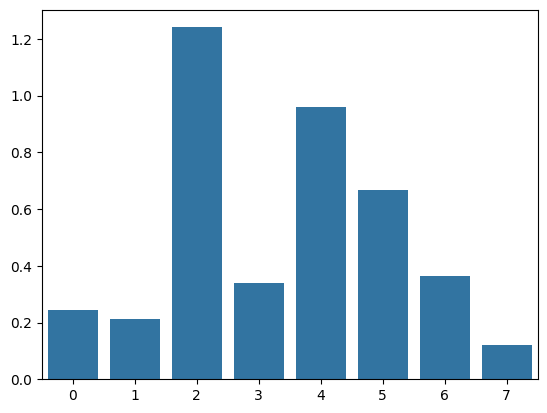

In [35]:
sns.barplot(np.abs(OLS.coef_))

In [36]:
OLS = LinearRegression()

OLS.fit(train.iloc[:,1:9],manifold.iloc[:,1])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


<Axes: >

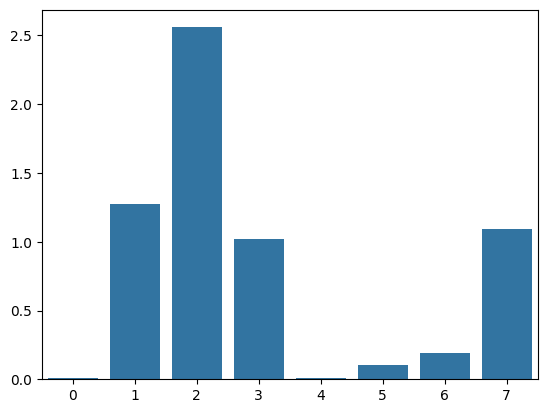

In [37]:
sns.barplot(np.abs(OLS.coef_))

In [38]:
train['Iso 1'] = manifold.iloc[:,0]
train['Iso 2'] = manifold.iloc[:,1]

train

C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\1794113043.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Iso 1'] = manifold.iloc[:,0]
C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\1794113043.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Iso 2'] = manifold.iloc[:,1]


,Time,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI,Target 1,Target 2,Target 3,Target 4,Bin Target Threshold Price,Bin Target Threshold BB Mid,Bin Target Threshold RSI,Iso 1,Iso 2
0,2011.12.22 00:00:00,1.270621,1.304233,1.286738,1.278058,1.743043,1.557840,1.354034,-1.067297,1.361063,1.322630,1.284197,33.699789,0,0,0,5.099925,1.506685
1,2011.12.23 00:00:00,1.277333,1.279712,1.295822,1.272276,1.692967,1.532652,1.354043,-1.087937,1.358734,1.320745,1.282755,34.205041,0,0,0,5.084401,1.503222
2,2011.12.26 00:00:00,1.275681,1.265952,1.319359,1.281466,1.662537,1.512875,1.345157,-1.027860,1.356674,1.318906,1.281138,33.180078,0,0,0,5.111439,1.503127
3,2011.12.27 00:00:00,1.280843,1.267090,1.312649,1.295509,1.641906,1.496914,1.334056,-0.932180,1.353412,1.317356,1.281301,42.674347,0,0,1,5.128719,1.499161
4,2011.12.28 00:00:00,1.295299,1.263675,1.177827,1.159829,1.634830,1.478828,1.305173,-1.445394,1.352429,1.315989,1.279549,37.132462,0,0,1,4.973239,1.541015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2814,2022.10.25 00:00:00,-2.005256,-1.945987,-1.984613,-1.908757,-2.077469,-2.100741,-2.099006,0.779182,1.003442,0.981559,0.959675,49.879315,0,0,0,-7.884957,4.947587
2815,2022.10.26 00:00:00,-1.911500,-1.830107,-1.886438,-1.786708,-2.061677,-2.097211,-2.107785,1.272910,1.003360,0.981491,0.959622,46.606188,0,0,0,-7.937394,4.962450
2816,2022.10.27 00:00:00,-1.795234,-1.825555,-1.871882,-1.909790,-2.065770,-2.098369,-2.105993,0.585168,1.003163,0.981190,0.959216,43.060989,0,0,0,-7.607721,4.750632
2817,2022.10.28 00:00:00,-1.910364,-1.924052,-1.903781,-1.907415,-2.071945,-2.100015,-2.103089,0.595317,1.004188,0.982094,0.960001,54.550446,0,0,0,-7.739006,4.847772


Text(0.5, 1.0, 'EURUSD Training Data Correlation Heatmap')

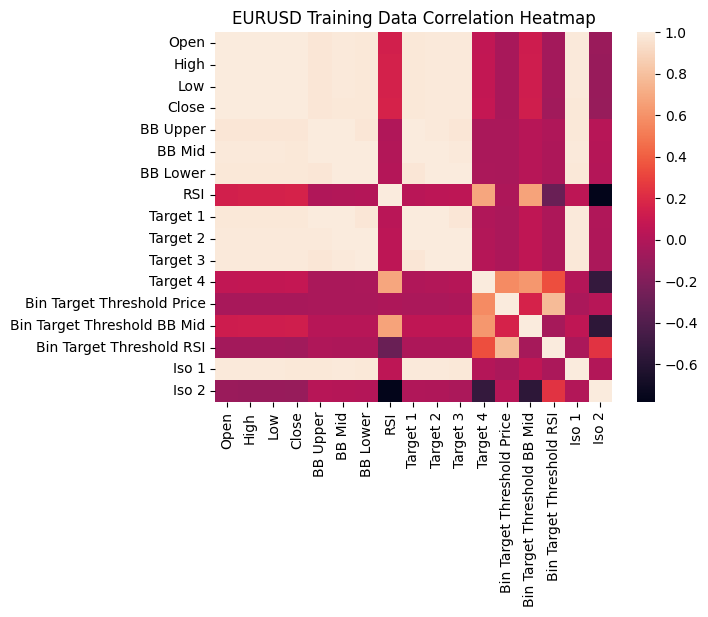

In [40]:
sns.heatmap(train.iloc[:,1:].corr())
plt.title('EURUSD Training Data Correlation Heatmap')

In [41]:
train['Bin Target 1'] = 0
train['Bin Target 2'] = 0

train.loc[train['Iso 1'].shift(-HORIZON) > train['Iso 1'],'Bin Target 1'] = 1
train.loc[train['Iso 2'].shift(-HORIZON) > train['Iso 2'],'Bin Target 2'] = 1

train = train.iloc[:-HORIZON,:]

train

C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\3009099923.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Bin Target 1'] = 0
C:\Users\Nyakonda Patricia\AppData\Local\Temp\ipykernel_13028\3009099923.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['Bin Target 2'] = 0


,Time,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI,Target 1,Target 2,Target 3,Target 4,Bin Target Threshold Price,Bin Target Threshold BB Mid,Bin Target Threshold RSI,Iso 1,Iso 2,Bin Target 1,Bin Target 2
0,2011.12.22 00:00:00,1.270621,1.304233,1.286738,1.278058,1.743043,1.557840,1.354034,-1.067297,1.361063,1.322630,1.284197,33.699789,0,0,0,5.099925,1.506685,0,1
1,2011.12.23 00:00:00,1.277333,1.279712,1.295822,1.272276,1.692967,1.532652,1.354043,-1.087937,1.358734,1.320745,1.282755,34.205041,0,0,0,5.084401,1.503222,0,0
2,2011.12.26 00:00:00,1.275681,1.265952,1.319359,1.281466,1.662537,1.512875,1.345157,-1.027860,1.356674,1.318906,1.281138,33.180078,0,0,0,5.111439,1.503127,0,0
3,2011.12.27 00:00:00,1.280843,1.267090,1.312649,1.295509,1.641906,1.496914,1.334056,-0.932180,1.353412,1.317356,1.281301,42.674347,0,0,1,5.128719,1.499161,0,0
4,2011.12.28 00:00:00,1.295299,1.263675,1.177827,1.159829,1.634830,1.478828,1.305173,-1.445394,1.352429,1.315989,1.279549,37.132462,0,0,1,4.973239,1.541015,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2809,2022.10.18 00:00:00,-2.038814,-2.050692,-2.021260,-2.019036,-2.000430,-2.070042,-2.115027,0.203878,1.005396,0.982281,0.959167,57.257790,1,0,1,-8.108811,5.140843,1,0
2810,2022.10.19 00:00:00,-2.022499,-2.054107,-2.078348,-2.107217,-2.013342,-2.078187,-2.118307,-0.231666,1.006914,0.982619,0.958323,62.742030,1,0,1,-7.737252,4.859356,0,1
2811,2022.10.20 00:00:00,-2.108408,-2.081835,-2.081445,-2.092761,-2.026326,-2.085585,-2.120029,-0.151832,1.006521,0.982508,0.958495,55.102714,1,0,1,-7.774351,4.882893,1,0
2812,2022.10.21 00:00:00,-2.094985,-2.057418,-2.132442,-2.013873,-2.044344,-2.091965,-2.114692,0.267041,1.005927,0.982351,0.958774,55.215444,1,0,1,-8.108782,5.139983,1,0


Text(0.5, 1.0, 'Visualizing Our High Dimensional Data in 2 Dimensions')

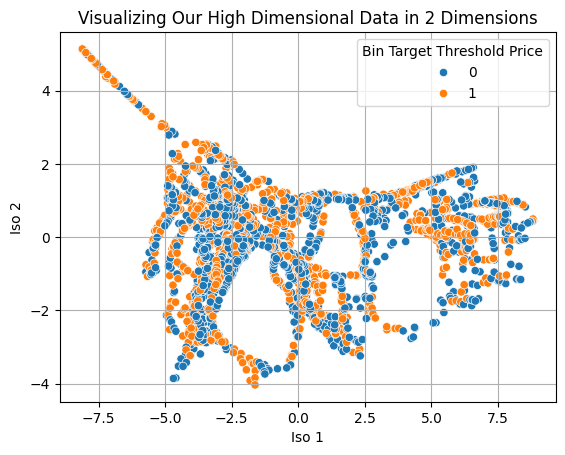

In [42]:
sns.scatterplot(data=train,x='Iso 1',y='Iso 2',hue='Bin Target Threshold Price')
plt.grid()
plt.title('Visualizing Our High Dimensional Data in 2 Dimensions')

In [46]:
train

,Time,Open,High,Low,Close,BB Upper,BB Mid,BB Lower,RSI,Target 1,Target 2,Target 3,Target 4,Bin Target Threshold Price,Bin Target Threshold BB Mid,Bin Target Threshold RSI,Iso 1,Iso 2,Bin Target 1,Bin Target 2
0,2011.12.22 00:00:00,1.270621,1.304233,1.286738,1.278058,1.743043,1.557840,1.354034,-1.067297,1.361063,1.322630,1.284197,33.699789,0,0,0,5.099925,1.506685,0,1
1,2011.12.23 00:00:00,1.277333,1.279712,1.295822,1.272276,1.692967,1.532652,1.354043,-1.087937,1.358734,1.320745,1.282755,34.205041,0,0,0,5.084401,1.503222,0,0
2,2011.12.26 00:00:00,1.275681,1.265952,1.319359,1.281466,1.662537,1.512875,1.345157,-1.027860,1.356674,1.318906,1.281138,33.180078,0,0,0,5.111439,1.503127,0,0
3,2011.12.27 00:00:00,1.280843,1.267090,1.312649,1.295509,1.641906,1.496914,1.334056,-0.932180,1.353412,1.317356,1.281301,42.674347,0,0,1,5.128719,1.499161,0,0
4,2011.12.28 00:00:00,1.295299,1.263675,1.177827,1.159829,1.634830,1.478828,1.305173,-1.445394,1.352429,1.315989,1.279549,37.132462,0,0,1,4.973239,1.541015,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2809,2022.10.18 00:00:00,-2.038814,-2.050692,-2.021260,-2.019036,-2.000430,-2.070042,-2.115027,0.203878,1.005396,0.982281,0.959167,57.257790,1,0,1,-8.108811,5.140843,1,0
2810,2022.10.19 00:00:00,-2.022499,-2.054107,-2.078348,-2.107217,-2.013342,-2.078187,-2.118307,-0.231666,1.006914,0.982619,0.958323,62.742030,1,0,1,-7.737252,4.859356,0,1
2811,2022.10.20 00:00:00,-2.108408,-2.081835,-2.081445,-2.092761,-2.026326,-2.085585,-2.120029,-0.151832,1.006521,0.982508,0.958495,55.102714,1,0,1,-7.774351,4.882893,1,0
2812,2022.10.21 00:00:00,-2.094985,-2.057418,-2.132442,-2.013873,-2.044344,-2.091965,-2.114692,0.267041,1.005927,0.982351,0.958774,55.215444,1,0,1,-8.108782,5.139983,1,0


In [43]:
scores = []

In [44]:
from sklearn.ensemble import RandomForestClassifier

In [45]:
scores.append(np.mean(np.abs(cross_val_score(RandomForestClassifier(),train.iloc[:,1:9],train['Bin Target Threshold Price'],cv=tscv,scoring='accuracy'))))

In [47]:
scores.append(np.mean(np.abs(cross_val_score(RandomForestClassifier(),train.iloc[:,1:9],train['Bin Target Threshold BB Mid'],cv=tscv,scoring='accuracy'))))

In [48]:
scores.append(np.mean(np.abs(cross_val_score(RandomForestClassifier(),train.iloc[:,1:9],train['Bin Target Threshold RSI'],cv=tscv,scoring='accuracy'))))

In [49]:
scores.append(np.mean(np.abs(cross_val_score(RandomForestClassifier(),train.iloc[:,1:9],train['Bin Target 1'],cv=tscv,scoring='accuracy'))))

In [50]:
scores.append(np.mean(np.abs(cross_val_score(RandomForestClassifier(),train.iloc[:,1:9],train['Bin Target 2'],cv=tscv,scoring='accuracy'))))

Text(0.5, 1.0, 'Our Accuracy Predicting Different Targets Related to The EURUSD')

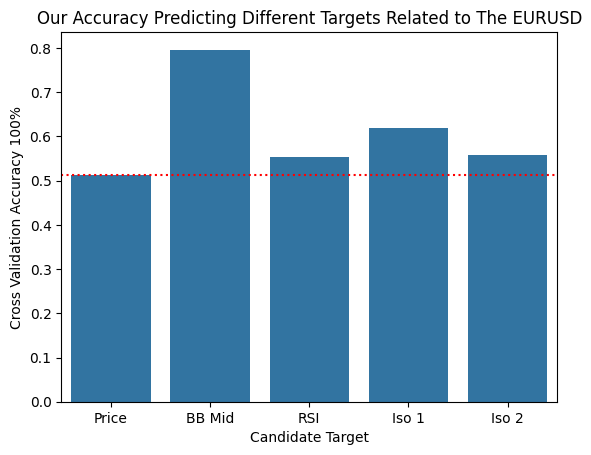

In [58]:
sns.barplot(scores)
plt.xticks([0,1,2,3,4],['Price','BB Mid','RSI','Iso 1','Iso 2'])
plt.axhline(scores[0],color='red',linestyle=':')
plt.ylabel('Cross Validation Accuracy 100%')
plt.xlabel('Candidate Target')
plt.title('Our Accuracy Predicting Different Targets Related to The EURUSD')

In [263]:
import onnx
from skl2onnx.common.data_types import FloatTensorType
from skl2onnx import convert_sklearn

In [264]:
initial_types = [('float_input',FloatTensorType([1,8]))]

In [265]:
final_types = [('float_output',FloatTensorType([1,1]))]

In [266]:
model = RandomForestRegressor()

model.fit(train.iloc[:,1:9],train['Bin Target 1'])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [267]:
onnx_proto = convert_sklearn(model,initial_types=initial_types,final_types=final_types,target_opset=12)

In [268]:
onnx.save(onnx_proto,"EURUSD D1 Iso 1 RandomForestRegressor.onnx")

In [269]:
Z1.values

array([ 1.18132371,  1.18577335,  1.17706596,  1.1812953 ,  1.20514458,
        1.18303579,  1.16092701, 48.60276562])

In [270]:
Z2.values

array([ 0.09684736,  0.09665192,  0.09686825,  0.09684589,  0.09614994,
        0.09556366,  0.09612185, 11.10783131])